# 10 — Xarici datasetlərlə yoxlama (cross-dataset)

Sual: format artefaktı (sqlmap-ə xas ikiqat boşluq) yalnız bizim datasetin xüsusiyyətidirmi və modellər artefaktı olmayan **müstəqil** datasetə necə köçür?

1. Ədəbiyyatda istifadə olunan digər açıq SQLi datasetlərinin bizimki ilə üst-üstə düşməsi.
2. `Modified_SQL_Dataset`-də öyrədilmiş modellərin **HttpParamsDataset** üzərində testi (sızma çıxarılmaqla).
3. Xarici datasetin zərərli sorğularına obfuskasiya (ssenari A).
4. Qara siyahı filtrinin real form dəyərlərində yanlış həyəcanı.
5. Əks istiqamət: HttpParams-da öyrədilmiş model bizim test dəstində.

In [1]:
import hashlib, re, sys, urllib.request
from pathlib import Path
from urllib.parse import unquote

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline

SEED = 42
np.random.seed(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import obfuscation as obf
from blacklist import flags, sanitize_input, sanitize_search
from normalize import human_format

PROC, RES, FIG, MODELS = (ROOT / p for p in ("data/processed", "results", "figures", "models"))
EXT = ROOT / "data" / "raw" / "external"

def save_fig(fig, name):
    fig.savefig(FIG / name, dpi=300, bbox_inches="tight")

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (c - h, c + h)

key = lambda s: re.sub(r"\s+", " ", str(s)).strip().lower()

## Məlumatın yüklənməsi
`data/raw/` git-də izlənmir. Fayllar yoxdursa, yüklənir; SHA-256 ilə versiya qeydə alınır.
- HttpParamsDataset: https://github.com/Morzeux/HttpParamsDataset (`payload_full.csv`)
- SQLiV3 / sqliv2 / sqli: Kaggle `syedsaqlainhussain/sql-injection-dataset` (versiya 5)

In [2]:
HP_URL = "https://raw.githubusercontent.com/Morzeux/HttpParamsDataset/master/payload_full.csv"
hp_path = EXT / "httpparams" / "payload_full.csv"
if not hp_path.exists():
    hp_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(HP_URL, hp_path)

v3_dir = EXT / "sqliv3"
if not (v3_dir / "SQLiV3.csv").exists():
    import shutil, kagglehub
    src = Path(kagglehub.dataset_download("syedsaqlainhussain/sql-injection-dataset/versions/5"))
    shutil.copytree(src, v3_dir, dirs_exist_ok=True)

EXPECTED = {
    "httpparams/payload_full.csv": "a4e62ba13435ad3dd583c5790db2175629020fc41c56e1b26baa02a9ae45f03d",
    "sqliv3/SQLiV3.csv": "c48b9e66fc9482817d5f2f42cbe47fa6a8f5a6f5199248cc635eaaa5bf0894ea",
    "sqliv3/sqliv2.csv": "335744e645438127cbf69ba38d4fe96da1959ea0c7ab593a985ad05fbb147820",
    "sqliv3/sqli.csv": "dc4c9d5dea6a4a7f4258b3cb3e3afacc77f4fd31a530ed1122a644f39b91238f",
}
for rel, h in EXPECTED.items():
    got = hashlib.sha256((EXT / rel).read_bytes()).hexdigest()
    print(f"{rel:30s} {'OK' if got == h else 'FƏRQLİ: ' + got}")

httpparams/payload_full.csv    OK
sqliv3/SQLiV3.csv              OK


sqliv3/sqliv2.csv              OK
sqliv3/sqli.csv                OK


In [3]:
def labelled(df, q, lab):
    d = df[[q, lab]].copy()
    d.columns = ["Query", "Label"]
    d["Label"] = pd.to_numeric(d["Label"], errors="coerce")
    d = d.dropna(subset=["Query"])
    d = d[d["Label"].isin([0, 1])].astype({"Label": int})
    d["Query"] = d["Query"].astype(str)
    return d.reset_index(drop=True)

ours = pd.read_csv(PROC / "clean_v2.csv")
train, val, test = (pd.read_csv(PROC / f"{s}_v2.csv") for s in ("train", "val", "test"))
v3 = labelled(pd.read_csv(v3_dir / "SQLiV3.csv"), "Sentence", "Label")
v2 = labelled(pd.read_csv(v3_dir / "sqliv2.csv", encoding="utf-16", on_bad_lines="skip"), "Sentence", "Label")
s1 = labelled(pd.read_csv(v3_dir / "sqli.csv", encoding="utf-16", on_bad_lines="skip"), "Sentence", "Label")
hp_raw = pd.read_csv(hp_path)
display(hp_raw.attack_type.value_counts())
hp = hp_raw[hp_raw.attack_type.isin(["norm", "sqli"])].assign(Label=lambda d: (d.attack_type == "sqli").astype(int))
hp = labelled(hp, "payload", "Label")

attack_type
norm              19304
sqli              10852
xss                 532
path-traversal      290
cmdi                 89
Name: count, dtype: int64

## 1. Datasetlərin üst-üstə düşməsi və artefakt
Üst-üstə düşmə: kiçik hərf + boşluqların birləşdirilməsindən sonra eyni sorğu `clean_v2`-də varmı.

In [4]:
ours_keys = set(ours.Query.map(key))
rows = []
for name, d in [("Modified_SQL_Dataset (clean_v2)", ours), ("SQLiV3", v3), ("sqliv2", v2),
                ("sqli", s1), ("HttpParamsDataset (sqli+norm)", hp)]:
    dbl = d.Query.str.contains("  ", regex=False)
    ov = d.Query.map(key).isin(ours_keys)
    m, c = d.Label == 1, d.Label == 0
    rows.append({"dataset": name, "n": len(d), "malicious": int(m.sum()), "clean": int(c.sum()),
                 "double_space_mal_pct": 100 * dbl[m].mean(), "double_space_clean_pct": 100 * dbl[c].mean(),
                 "overlap_mal_pct": 100 * ov[m].mean(), "overlap_clean_pct": 100 * ov[c].mean()})
overlap = pd.DataFrame(rows).round(1)
overlap.to_csv(RES / "10_dataset_overlap.csv", index=False)
overlap

,dataset,n,malicious,clean,double_space_mal_pct,double_space_clean_pct,overlap_mal_pct,overlap_clean_pct
0,Modified_SQL_Dataset (clean_v2),30255,11370,18885,94.9,29.8,100.0,100.0
1,SQLiV3,30609,11341,19268,95.0,28.5,99.9,96.6
2,sqliv2,33757,11453,22304,80.0,0.0,98.4,32.3
3,sqli,4187,1127,3060,34.3,0.3,81.4,1.3
4,HttpParamsDataset (sqli+norm),30156,10852,19304,0.0,0.0,3.6,37.3


SQLiV3 və sqliv2 bizim datasetlə demək olar ki, eynidir (zərərli sinif ≥ 98%) — müstəqil yoxlama üçün yararsızdır.
HttpParamsDataset müstəqildir və ikiqat boşluq artefaktı **yoxdur**. Onun payload-ları da sqlmap mənşəlidir, təmiz sinfi isə real veb form dəyərləridir.

## 2. Cross-dataset test: Modified_SQL_Dataset → HttpParamsDataset
Sızmanın qarşısını almaq üçün bizim train/val dəstlərində olan sorğular çıxarılır.

In [5]:
seen = set(pd.concat([train.Query, val.Query]).map(key))
hp_u = hp.drop_duplicates("Query")
hp_eval = hp_u[~hp_u.Query.map(key).isin(seen)].reset_index(drop=True)
print(f"HttpParams sqli+norm: {len(hp)}  unikal: {len(hp_u)}  sızmasız: {len(hp_eval)}  "
      f"(zərərli {hp_eval.Label.sum()}, təmiz {(hp_eval.Label == 0).sum()})")

MODEL_FILES = {"LR baza": "lr_v2", "SVM baza": "svm_v2", "RF baza": "rf_v2", "NB baza": "nb_v2",
               "LR + normallaşdırma": "lr_norm_v2", "LR + norm. + augmentation": "lr_norm_aug_v2"}
models = {n: joblib.load(MODELS / f"{f}.joblib") for n, f in MODEL_FILES.items()}

def score(y, p):
    y, p = np.asarray(y), np.asarray(p)
    tp, fn = int(((p == 1) & (y == 1)).sum()), int(((p == 0) & (y == 1)).sum())
    fp, tn = int(((p == 1) & (y == 0)).sum()), int(((p == 0) & (y == 0)).sum())
    r_lo, r_hi = wilson(tp, tp + fn)
    f_lo, f_hi = wilson(fp, fp + tn)
    return {"recall": tp / (tp + fn), "recall_ci_low": r_lo, "recall_ci_high": r_hi,
            "fpr": fp / (fp + tn), "fpr_ci_low": f_lo, "fpr_ci_high": f_hi,
            "f1": f1_score(y, p), "fn": fn, "fp": fp}

rows = []
for name, m in models.items():
    for ds_name, ds in [("our test", test), ("HttpParams", hp_eval)]:
        rows.append({"model": name, "dataset": ds_name, **score(ds.Label, m.predict(ds.Query))})
cross = pd.DataFrame(rows)
cross.to_csv(RES / "10_cross_dataset.csv", index=False)
cross.pivot(index="model", columns="dataset", values=["recall", "fpr", "f1"]).loc[list(MODEL_FILES)].round(4)

HttpParams sqli+norm: 30156  unikal: 30156  sızmasız: 23720  (zərərli 10531, təmiz 13189)


recall                 fpr                  f1  \
dataset                   HttpParams our test HttpParams our test HttpParams   
model                                                                          
LR baza                       0.9725   0.9960     0.0003   0.0011     0.9858   
SVM baza                      0.9718   0.9960     0.0002   0.0007     0.9856   
RF baza                       0.9504   0.9931     0.0002   0.0007     0.9745   
NB baza                       0.9904   0.9891     0.2941   0.0773     0.8398   
LR + normallaşdırma           0.9998   0.9948     0.0003   0.0014     0.9997   
LR + norm. + augmentation     0.9998   0.9937     0.0003   0.0007     0.9997   

                                    
dataset                   our test  
model                               
LR baza                     0.9971  
SVM baza                    0.9974  
RF baza                     0.9960  
NB baza                     0.9363  
LR + normallaşdırma         0.9963  
LR + norm. + augmentation   0.9963

### Hansı hücumlar qaçırılır?
Baza LR-in HttpParams-da buraxdığı payload-lar artefakt baxımından: bizim datasetin formatına (sqlmap boşluqları) gətirildikdə tutulurmu?

In [6]:
def sqlmap_spacing(q):
    # bizim datasetin formatı: = ( ) ətrafında ikiqat boşluq
    q = re.sub(r"\s*([=()])\s*", r"  \1  ", q)
    return re.sub(r" {3,}", "  ", q).strip()

lr = models["LR baza"]
mal_hp = hp_eval[hp_eval.Label == 1].Query
missed = mal_hp[lr.predict(mal_hp) == 0]
recovered = lr.predict(missed.map(sqlmap_spacing)).mean()
print(f"LR baza qaçırdı: {len(missed)} / {len(mal_hp)}")
print(f"Həmin payload-lar sqlmap boşluq formatına salındıqda tutulma: {100 * recovered:.1f}%")
art = pd.DataFrame([{"missed_by_lr_baseline": len(missed), "n_malicious": len(mal_hp),
                     "recovered_after_sqlmap_spacing_pct": 100 * recovered}])
art.to_csv(RES / "10_artifact_injection_test.csv", index=False)
missed.sample(min(10, len(missed)), random_state=SEED).tolist()

LR baza qaçırdı: 290 / 10531
Həmin payload-lar sqlmap boşluq formatına salındıqda tutulma: 99.3%


['1") where 4964=4964;(select * from (select(sleep(5)))srmq)--',
 '1%"))) rlike (select * from (select(sleep(5)))vwyq)#',
 '1%")));(select * from (select(sleep(5)))acdk)#',
 '1) rlike (select * from (select(sleep(5)))vwyq)#',
 '1")));(select * from (select(sleep(5)))acdk)#',
 "1'+(select qpaf where 7859=7859 or (select * from (select(sleep(5)))ydpu))+'",
 "1') where 2928=2928 and (select * from (select(sleep(5)))gcrr)#",
 '1" rlike (select * from (select(sleep(5)))sgvo)',
 "1');(select * from (select(sleep(5)))srmq) and ('kerg' like 'kerg",
 'iif(1539=1539,1539,1/0)']

## 3. Xarici datasetdə obfuskasiya (ssenari A)
`src/obfuscation.py` HttpParams-ın sızmasız zərərli sorğularına tətbiq olunur; model girişi bir dəfə `unquote` edilir. `keyword_split_comment` MySQL-də etibarsızdır, ona görə ayrıca qeyd olunur.

In [7]:
TECHS = list(obf.TECHNIQUES) + ["combination"]
mal_list = mal_hp.tolist()
rows = []
for tech in TECHS:
    r = pd.DataFrame(obf.apply_technique(tech, mal_list, seed=SEED))
    r = r[r.changed]
    x = r.obfuscated.map(unquote)
    for name, m in models.items():
        if name in ("SVM baza", "NB baza"):
            continue
        rows.append({"technique": tech, "n": len(r), "model": name, "recall": m.predict(x).mean()})
for name, m in models.items():
    if name not in ("SVM baza", "NB baza"):
        rows.append({"technique": "original", "n": len(mal_list), "model": name,
                     "recall": m.predict(mal_hp.map(unquote)).mean()})
cross_obf = pd.DataFrame(rows)
cross_obf.to_csv(RES / "10_cross_obfuscation_A.csv", index=False)
tab = cross_obf.pivot_table(index=["technique", "n"], columns="model", values="recall").mul(100).round(1)
tab = tab[[c for c in MODEL_FILES if c in tab.columns]]
tab.sort_values("LR baza")

,model,LR baza,RF baza,LR + normallaşdırma,LR + norm. + augmentation
technique,n,,,,
alt_whitespace,10457,83.4,38.7,100.0,100.0
alt_whitespace_url,10457,83.4,38.7,100.0,100.0
original,10531,97.2,95.0,100.0,100.0
url_encode,10529,97.3,95.1,100.0,100.0
double_url_encode,10529,97.4,12.0,100.0,100.0
random_case,10457,97.4,95.4,100.0,100.0
logical_operator,6599,97.5,93.8,100.0,100.0
combination,10365,97.6,59.2,100.0,100.0
hex_strings,3807,98.8,95.2,100.0,100.0


## 4. Qara siyahı filtri real form dəyərlərində
HttpParams-ın təmiz sinfi (ünvan, ad, rəqəm və s.) bizim datasetin SQL-dən ibarət təmiz sinfindən daha real FPR verir.

In [8]:
rows = []
for name, fn in [("Blacklist (Input)", sanitize_input), ("Blacklist (Search)", sanitize_search)]:
    p = hp_eval.Query.map(lambda q: int(flags(q, fn)))
    rows.append({"model": name, "dataset": "HttpParams", **score(hp_eval.Label, p)})
bl = pd.DataFrame(rows)
bl.to_csv(RES / "10_blacklist_httpparams.csv", index=False)
fp_examples = hp_eval[(hp_eval.Label == 0) & hp_eval.Query.map(lambda q: flags(q, sanitize_input))].Query
print(fp_examples.sample(min(10, len(fp_examples)), random_state=SEED).tolist())
bl.round(4)

['calle can bordoi, 148', 'casiodoro', 'sandi', 'spaeth@directoriogratuito.kr', 'kavanaugh@corjet.org', 'gandolfo', 'anoux_corsia@906.com.cz', 'porta aylagas', 'alcalde isidoro enciso, 100 6?g', 'nelson@coreserv.cf']


,model,dataset,recall,recall_ci_low,recall_ci_high,fpr,fpr_ci_low,fpr_ci_high,f1,fn,fp
0,Blacklist (Input),HttpParams,0.9949,0.9933,0.9961,0.0868,0.0821,0.0917,0.9459,54,1145
1,Blacklist (Search),HttpParams,0.9639,0.9602,0.9673,0.0023,0.0016,0.0032,0.9802,380,30


## 5. Əks istiqamət: HttpParamsDataset → Modified_SQL_Dataset
HttpParams-da (qrup əsaslı bölgü, eyni TF-IDF + LR) öyrədilmiş model bizim test dəstində və onun "insan formatı" variantında.
Artefaktsız datada öyrədilmiş model format dəyişikliyinə həssas olmamalıdır.

In [9]:
groups = hp_u.Query.map(key)
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED).split(hp_u, groups=groups))
hp_tr = hp_u.iloc[tr_idx]
lr_hp = Pipeline([("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(1, 5), lowercase=True,
                                            sublinear_tf=True, min_df=2, dtype=np.float32)),
                  ("clf", LogisticRegression(C=10, max_iter=2000, random_state=SEED))]).fit(hp_tr.Query, hp_tr.Label)

test_h = test.assign(Query=test.Query.map(human_format))
rows = []
for mname, m in [("LR (HttpParams-da öyrədilib)", lr_hp), ("LR baza (bizim datasetdə)", models["LR baza"])]:
    for ds_name, ds in [("HttpParams test", hp_u.iloc[te_idx]), ("our test", test), ("our test, human format", test_h)]:
        rows.append({"model": mname, "dataset": ds_name, **score(ds.Label, m.predict(ds.Query))})
rev = pd.DataFrame(rows)
rev.to_csv(RES / "10_reverse_direction.csv", index=False)
rev[["model", "dataset", "recall", "fpr", "f1"]].round(4)

,model,dataset,recall,fpr,f1
0,LR (HttpParams-da öyrədilib),HttpParams test,0.9994,0.0000,0.9997
1,LR (HttpParams-da öyrədilib),our test,0.9857,0.5200,0.6995
2,LR (HttpParams-da öyrədilib),"our test, human format",0.9771,0.4807,0.7115
3,LR baza (bizim datasetdə),HttpParams test,0.9771,0.0000,0.9884
4,LR baza (bizim datasetdə),our test,0.9960,0.0011,0.9971
5,LR baza (bizim datasetdə),"our test, human format",0.9255,0.0014,0.9602


## 6. HttpParams nə dərəcədə müstəqildir?
Format xüsusiyyətləri hər iki datasetdə və hər iki sinifdə; sonra **şablon üst-üstə düşməsi**: rəqəmlər → `N`, hex → `H`,
sqlmap-in təsadüfi 4 hərfli teqləri (`'abcd'`) → `'S'`, bütün whitespace silinir. Bu formada HttpParams-ın zərərli sorğusu
bizim datasetin zərərli sorğuları arasında varsa, deməli eyni sqlmap şablonudur — yalnız formatı fərqlidir.

In [10]:
def template(q):
    q = q.lower()
    q = re.sub(r"0x[0-9a-f]+", "H", q)
    q = re.sub(r"\d+", "N", q)
    q = re.sub(r"(['\"])[a-z]{4}\1", r"\1S\1", q)
    return re.sub(r"\s+", "", q)

rows = []
for name, d in [("Modified_SQL_Dataset", ours), ("HttpParamsDataset", hp)]:
    for lab, cls in ((1, "zərərli"), (0, "təmiz")):
        q = d.loc[d.Label == lab, "Query"]
        rows.append({"dataset": name, "class": cls, "n": len(q),
                     "double_space_pct": 100 * q.str.contains("  ", regex=False).mean(),
                     "space_around_eq_pct": 100 * q.str.contains(" = ", regex=False).mean(),
                     "space_inside_paren_pct": 100 * q.str.contains(r"\( | \)", regex=True).mean(),
                     "has_uppercase_pct": 100 * q.str.contains(r"[A-Z]", regex=True).mean(),
                     "median_len": q.str.len().median()})
fmt = pd.DataFrame(rows).round(1)
ours_t = set(ours.loc[ours.Label == 1, "Query"].map(template))
hp_mal_t = hp_eval.loc[hp_eval.Label == 1, "Query"].map(template)
tmpl_share = 100 * hp_mal_t.isin(ours_t).mean()
fmt["template_overlap_with_ours_pct"] = [np.nan, np.nan, round(tmpl_share, 1), np.nan]
fmt.to_csv(RES / "10_httpparams_independence.csv", index=False)
print(f"HttpParams (sızmasız) zərərli sorğularının bizim zərərli şablonlarla üst-üstə düşməsi: {tmpl_share:.1f}%")
fmt

HttpParams (sızmasız) zərərli sorğularının bizim zərərli şablonlarla üst-üstə düşməsi: 78.4%


,dataset,class,n,double_space_pct,space_around_eq_pct,space_inside_paren_pct,has_uppercase_pct,median_len,template_overlap_with_ours_pct
0,Modified_SQL_Dataset,zərərli,11370,94.9,81.1,86.9,2.0,85.5,NaN
1,Modified_SQL_Dataset,təmiz,18885,29.8,14.8,24.4,61.3,37.0,NaN
2,HttpParamsDataset,zərərli,10852,0.0,0.0,0.0,0.0,75.0,78.4
3,HttpParamsDataset,təmiz,19304,0.0,0.0,0.0,0.0,9.0,NaN


**Nəticə (dürüst izah).** HttpParams-ın zərərli sorğuları da sqlmap tərəfindən yaradılıb: sızmasız dəstin zərərli sorğularının
təxminən 4/5-i whitespace və rəqəmlər nəzərə alınmadıqda bizim datasetdəki eyni sqlmap şablonlarıdır. Fərq yalnız formatdadır:
HttpParams-da ikiqat boşluq, `=` ətrafında və mötərizə daxilində boşluq yoxdur (hər iki sinifdə 0%), bütün mətn kiçik hərfdir.
Deməli, bu test **yeni hücum növlərinə ümumiləşməni yox**, eyni hücumların **başqa formatda** tanınmasını ölçür — yəni format
artefaktı hipotezinin təbii sınağıdır. Təmiz sinfi isə real, qısa form dəyərləridir (median 9 simvol, SQL yoxdur), ona görə
HttpParams-dakı aşağı FPR bizim datasetdəki SQL ifadələrindən ibarət təmiz sinifdəki FPR ilə birbaşa müqayisə olunmamalıdır.

## Şəkil

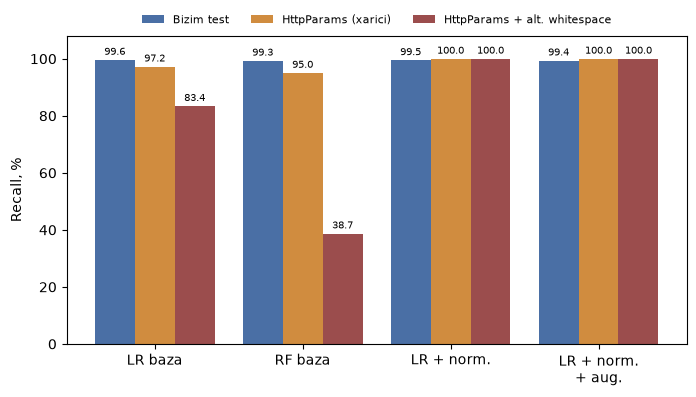

In [11]:
order = ["LR baza", "RF baza", "LR + normallaşdırma", "LR + norm. + augmentation"]
p = cross.pivot(index="model", columns="dataset", values="recall").loc[order] * 100
aw = cross_obf[cross_obf.technique == "alt_whitespace"].set_index("model").recall.loc[order] * 100
fig, ax = plt.subplots(figsize=(8, 4))
x, w = np.arange(len(order)), 0.27
for i, (lab, vals, col) in enumerate([("Bizim test", p["our test"], "#4a6fa5"),
                                       ("HttpParams (xarici)", p["HttpParams"], "#d08c3f"),
                                       ("HttpParams + alt. whitespace", aw, "#9b4d4d")]):
    b = ax.bar(x + (i - 1) * w, vals, w, label=lab, color=col)
    ax.bar_label(b, fmt="%.1f", fontsize=7, padding=2)
ax.set_xticks(x, ["LR baza", "RF baza", "LR + norm.", "LR + norm.\n+ aug."])
ax.set_ylabel("Recall, %")
ax.set_ylim(0, 108)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, fontsize=8, frameon=False)
save_fig(fig, "10_cross_dataset_recall.png")
plt.show()